<a href="https://colab.research.google.com/github/berevai/METODOS-NUMERICOS/blob/main/Diferencias_Divididas_Newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

$\color{red}{\huge \textbf{Fórmula de las Diferencias Divididas de Newton}}$

$\color{#0035D9}{\textbf{Algoritmo 3.2 — Burden \& Faires, Análisis Numérico, Cap. 3}}$

$\color{#006B35}{\textbf{Materia:}}$ Métodos Numéricos  
$\color{#006B35}{\textbf{Autor:}}$ *Rubio Ortega Berenice*  
$\color{#006B35}{\textbf{Fecha:}}$ 19/11/26

$\color{#0035D9}{\textbf{Formulación del problema}}$

Dada una función $f$ de la que solo conocemos sus valores en $n+1$ nodos distintos $x_0, x_1, \dots, x_n$, queremos encontrar el polinomio de interpolación $P_n$ de grado a lo sumo $n$ que cumple

$$P_n(x_i) = f(x_i), \qquad i = 0, 1, \dots, n.$$

$\color{#006B35}{\textbf{Diferencia con Neville:}}$ el método de Neville solo *evalúa* $P(x)$ en un punto. Aquí obtenemos los **coeficientes** del polinomio, así que podemos escribirlo, graficarlo y evaluarlo en cualquier $x$.

$\color{#0035D9}{\textbf{La fórmula de las diferencias divididas de Newton}}$

La **diferencia dividida cero** de $f$ en $x_i$ es simplemente $f[x_i] = f(x_i)$. Las siguientes se definen de forma recursiva:

$$f[x_0, x_1] = \frac{f[x_1] - f[x_0]}{x_1 - x_0}, \qquad f[x_0, x_1, x_2] = \frac{f[x_1, x_2] - f[x_0, x_1]}{x_2 - x_0}, \;\dots$$

Si usamos la notación $F_{i,j} = f[x_{i-j}, \dots, x_i]$, entonces:

$$\boxed{F_{i,0} = f(x_i)} \qquad\qquad \boxed{F_{i,j} = \frac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}} \quad 1 \le j \le i \le n$$

Los coeficientes del polinomio son los de la **diagonal** de la tabla, y el polinomio de Newton es

$$P_n(x) = F_{0,0} + \sum_{i=1}^{n} F_{i,i} \prod_{j=0}^{i-1} (x - x_j)$$

es decir,

$$P_n(x) = F_{0,0} + F_{1,1}(x-x_0) + F_{2,2}(x-x_0)(x-x_1) + \dots + F_{n,n}(x-x_0)\cdots(x-x_{n-1}).$$

| $x_i$ | $F_{i,0}$ | $F_{i,1}$ | $F_{i,2}$ | $F_{i,3}$ | $F_{i,4}$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $x_0$ | $\color{red}{F_{0,0}}$ | | | | |
| $x_1$ | $F_{1,0}$ | $\color{red}{F_{1,1}}$ | | | |
| $x_2$ | $F_{2,0}$ | $F_{2,1}$ | $\color{red}{F_{2,2}}$ | | |
| $x_3$ | $F_{3,0}$ | $F_{3,1}$ | $F_{3,2}$ | $\color{red}{F_{3,3}}$ | |
| $x_4$ | $F_{4,0}$ | $F_{4,1}$ | $F_{4,2}$ | $F_{4,3}$ | $\color{red}{F_{4,4}}$ |

Los números en rojo (la diagonal) son los coeficientes que devuelve el algoritmo.

$\color{#0035D9}{\textbf{Algoritmo 3.2}}$

**ENTRADA:** nodos $x_0, \dots, x_n$ y valores $f(x_0), \dots, f(x_n)$ como primera columna $F_{0,0}, \dots, F_{n,0}$.  
**SALIDA:** los números $F_{0,0}, F_{1,1}, \dots, F_{n,n}$ (coeficientes de $P_n$).

1. Para $i = 1, 2, \dots, n$ y para $j = 1, 2, \dots, i$ hacer $F_{i,j} = \dfrac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}$
2. SALIDA $(F_{0,0}, F_{1,1}, \dots, F_{n,n})$; PARAR.

Importamos librerías:

In [1]:
import numpy as np
import matplotlib.pyplot as plt   # gráficas
import sympy as sp

# Opcional: pandas solo sirve para mostrar tablas bonitas.
try:
    import pandas as pd
except ImportError:
    pd = None

$\color{#0035D9}{\textbf{Función diferencias\_divididas}}$

Notas de sintaxis:
- `def` define una función; los parámetros van entre paréntesis.
- `np.asarray(..., dtype=float)` convierte una lista en un arreglo de números reales.
- `np.zeros((m, m))` crea una matriz de $m\times m$ llena de ceros.
- `F[:, 0] = f_nodos` llena **toda la columna 0** de la matriz.
- `range(1, n+1)` genera $1,2,\dots,n$ (el límite superior **no** se incluye).
- `F[i, j]` accede a la fila `i`, columna `j`.
- `np.diag(F)` extrae la diagonal de la matriz.

In [2]:
def diferencias_divididas(x_nodos, f_nodos):
    '''
    Fórmula de las diferencias divididas de Newton (Algoritmo 3.2, Burden).

    Entrada: nodos x_i y valores f(x_i).
    Salida:  tabla F; los coeficientes del polinomio son la diagonal F[i, i].
    '''
    x_nodos = np.asarray(x_nodos, dtype=float)   # pasamos a arreglos de reales
    f_nodos = np.asarray(f_nodos, dtype=float)
    n = len(x_nodos) - 1                          # n+1 nodos -> grado n

    F = np.zeros((n + 1, n + 1))                  # tabla F llena de ceros
    F[:, 0] = f_nodos                             # primera columna: F_{i,0} = f(x_i)

    for i in range(1, n + 1):                     # i = 1, ..., n
        for j in range(1, i + 1):                 # j = 1, ..., i
            F[i, j] = (F[i, j - 1] - F[i - 1, j - 1]) / (x_nodos[i] - x_nodos[i - j])

    return F

$\color{#0035D9}{\textbf{Función polinomio\_newton (con sympy)}}$

Esta función toma los **coeficientes** (la diagonal de $F$), construye el polinomio de forma simbólica, lo escribe y lo grafica.

Notas de sintaxis de `sympy`:
- `sp.Symbol('x')` crea la variable simbólica $x$.
- `sp.Float(a)` convierte un número de Python en un número de sympy.
- `sp.expand(P)` desarrolla el polinomio en potencias de $x$.
- `sp.latex(P)` convierte la expresión a código LaTeX.
- `sp.lambdify(x, P, 'numpy')` convierte la expresión en una función numérica rápida, que podemos evaluar en muchos puntos a la vez.
- `display(Math(...))` muestra una fórmula LaTeX bonita en el cuaderno.

In [3]:
from IPython.display import display, Math

def polinomio_newton(x_nodos, coef, graficar=True):
    '''
    Construye, escribe y grafica el polinomio de Newton.

    Entrada: nodos x_i y coeficientes F_{i,i} (diagonal de la tabla).
    Salida:  (x, P) con x el símbolo y P la expresión simbólica de P_n(x).
    '''
    x = sp.Symbol('x')                       # variable simbólica
    P = sp.Float(coef[0])                    # F_{0,0}
    producto = sp.Integer(1)                 # aquí iremos acumulando (x-x0)(x-x1)...

    for i in range(1, len(coef)):
        producto = producto * (x - sp.Float(x_nodos[i - 1]))   # agrega el factor (x - x_{i-1})
        P = P + sp.Float(coef[i]) * producto                    # suma F_{i,i} * producto

    # Escribimos el polinomio en forma de Newton y en forma desarrollada
    display(Math(r"P_{%d}(x) = " % (len(coef) - 1) + sp.latex(P)))
    print("Forma desarrollada:")
    display(Math(r"P_{%d}(x) = " % (len(coef) - 1) + sp.latex(sp.expand(P))))

    if graficar:
        f_num = sp.lambdify(x, P, 'numpy')                       # P como función numérica
        t = np.linspace(min(x_nodos) - 0.1, max(x_nodos) + 0.1, 300)
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(t, f_num(t), color="#0035D9", lw=2.5, label=r"$P_n(x)$ de Newton")
        ax.scatter(x_nodos, [f_num(xi) for xi in x_nodos], color="black", zorder=5, s=60, label="Nodos")
        ax.set_title("Polinomio de interpolación de Newton", fontsize=14)
        ax.set_xlabel("x")
        ax.set_ylabel("P(x)")
        ax.grid(alpha=0.3)
        ax.legend()
        plt.show()

    return x, P

$\color{#0035D9}{\textbf{Ejemplo de prueba}}$

Para probar el método, utilizaremos el **Ejemplo 1 de la página 94** del libro de Burden.

Completar la tabla de diferencias divididas para los datos de la Tabla 3.10 y construir el polinomio de interpolación que usa todos los datos:

| $x$ | 1.0 | 1.3 | 1.6 | 1.9 | 2.2 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $f(x)$ | 0.7651977 | 0.6200860 | 0.4554022 | 0.2818186 | 0.1103623 |

In [4]:
# Datos de la Tabla 3.10
x_nodos = [1.0, 1.3, 1.6, 1.9, 2.2]
f_nodos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

# Aplicamos el algoritmo
F = diferencias_divididas(x_nodos, f_nodos)

Veamos la tabla completa que se generó. Debe coincidir con la **Tabla 3.11** del libro:

In [5]:
np.set_printoptions(precision=7, suppress=True)

if pd is not None:
    columnas = ["f[xi]", "f[xi-1, xi]", "f[xi-2,...,xi]", "f[xi-3,...,xi]", "f[xi-4,...,xi]"]
    tabla = pd.DataFrame(F, columns=columnas, index=pd.Index(x_nodos, name="x_i"))
    # Los ceros sobre la diagonal (parte no usada) se muestran vacíos
    display(tabla.round(7).replace(0.0, np.nan).fillna("").style.format(precision=7))
else:
    print(F)

,f[xi],"f[xi-1, xi]","f[xi-2,...,xi]","f[xi-3,...,xi]","f[xi-4,...,xi]"
x_i,,,,,
1.000000,0.7651977,,,,
1.300000,0.6200860,-0.4837057,,,
1.600000,0.4554022,-0.5489460,-0.1087339,,
1.900000,0.2818186,-0.5786120,-0.0494433,0.0658784,
2.200000,0.1103623,-0.5715210,0.0118183,0.0680685,0.0018251


Para estar seguros, comparamos con los valores de la Tabla 3.11 del libro:

In [6]:
# Tabla 3.11 del libro (7 decimales)
F_libro = np.array([
    [0.7651977,  0,          0,          0,         0        ],
    [0.6200860, -0.4837057,  0,          0,         0        ],
    [0.4554022, -0.5489460, -0.1087339,  0,         0        ],
    [0.2818186, -0.5786120, -0.0494433,  0.0658784, 0        ],
    [0.1103623, -0.5715210,  0.0118183,  0.0680685, 0.0018251],
])

error_max = np.max(np.abs(F - F_libro))
print(f"Máxima diferencia con la Tabla 3.11: {error_max:.2e}")
print("¿Coincide con el libro?", error_max < 1e-6)

Máxima diferencia con la Tabla 3.11: 3.33e-08
¿Coincide con el libro? True


$\color{#0035D9}{\textbf{Coeficientes del polinomio}}$

Los coeficientes son los elementos de la **diagonal** de la tabla $F_{0,0}, F_{1,1}, \dots, F_{4,4}$:

In [7]:
coef = np.diag(F)    # diagonal de la tabla = coeficientes de Newton

for i, c in enumerate(coef):
    print(f"F[{i},{i}] = {c: .7f}")

F[0,0] =  0.7651977
F[1,1] = -0.4837057
F[2,2] = -0.1087339
F[3,3] =  0.0658784
F[4,4] =  0.0018251


$\color{#0035D9}{\textbf{Solución: polinomio de Newton}}$

Ahora usamos la función `polinomio_newton` para escribir y graficar el polinomio:

<IPython.core.display.Math object>

Forma desarrollada:


<IPython.core.display.Math object>

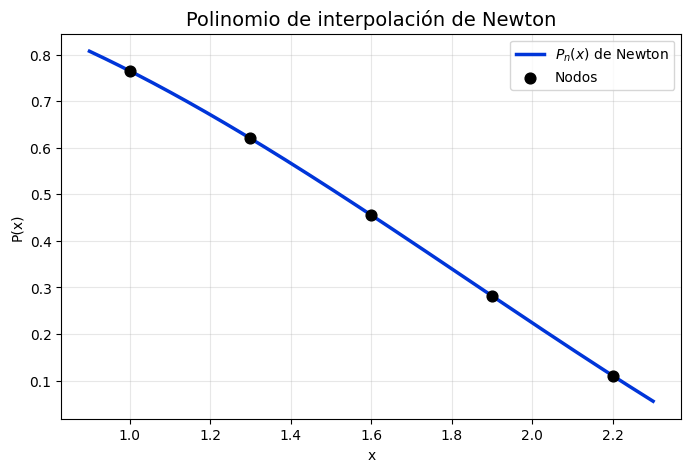

In [8]:
x_sym, P = polinomio_newton(x_nodos, coef)

$\color{#0035D9}{\textbf{Verificación}}$

El libro obtiene

$$P_4(x) = 0.7651977 - 0.4837057(x-1.0) - 0.1087339(x-1.0)(x-1.3) + 0.0658784(x-1.0)(x-1.3)(x-1.6) + 0.0018251(x-1.0)(x-1.3)(x-1.6)(x-1.9)$$

y observa que $P_4(1.5) = 0.5118200$, que coincide con el resultado del método de Neville (Tabla 3.6). Lo comprobamos evaluando nuestro polinomio:

In [9]:
valor = float(P.subs(x_sym, 1.5))     # .subs sustituye x por 1.5 en la expresión simbólica

print("=" * 45)
print(f"  P4(1.5) = {valor:.7f}")
print("  Libro   = 0.5118200")
print("=" * 45)

  P4(1.5) = 0.5118200
  Libro   = 0.5118200


<div style="background:#e8f5e9;border-left:6px solid #2e7d32;padding:12px;border-radius:6px">
$\color{#006B35}{\textbf{Solución Final:}}$ los coeficientes de Newton son
$0.7651977,\ -0.4837057,\ -0.1087339,\ 0.0658784,\ 0.0018251$, y el polinomio satisface
$P_4(1.5) \approx \mathbf{0.5118200}$, igual que Neville.
</div>

$\color{#0035D9}{\textbf{Conclusiones}}$

- El algoritmo 3.2 devuelve los **coeficientes** del polinomio de Newton (la diagonal de la tabla de diferencias divididas).
- Nuestra tabla reproduce exactamente la **Tabla 3.11** del libro.
- Con `sympy` escribimos el polinomio de forma simbólica y lo graficamos.
- $P_4(1.5) = 0.5118200$ coincide con Neville, porque ambos métodos construyen **el mismo polinomio** de interpolación.
- Ventaja sobre Neville: una vez calculados los coeficientes, podemos evaluar $P_n$ en **cualquier** $x$ sin repetir el algoritmo.

*Referencia: Burden & Faires, Análisis Numérico, Sección 3.3.*